<a href="https://colab.research.google.com/github/AgeNNortoN/Tugas-1_Machine-Learning/blob/main/Tugas2_eddyfranc.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**<center>$\color{green}{\text{TUGAS 2 : KLASIFIKASI}}$</center>**

>
Nama: H. Eddy Franc

NIM : 055398554

S1 Data Sains Universitas Terbuka

Machine Learning



---


<p>
Universitas Terbuka adalah sebuah perguruan tinggi terbuka yang memberikan kesempatan bagi putra putri bangsa untuk menimba ilmu dan pengetahuan. UT memiliki mahasiswa dengan latar belakang yang beragam. Mahasiswanya tidak terbatas pada lulusan baru dari sma/smu/smk sederajat. Beberapa diantaranya bahkan telah/sedang bekerja. Kondisi tersebut memberikan kesulitan bagi pihak kampus dalam menerapkan strategi untuk membantu mahasiswa berhasil melewati masa kuliah dan lulus tepat waktu.
</p>

<p>
Sebagai seorang Machine Learning engineer, kamu diminta untuk membuat model yang mampu mendeteksi secara dini tigkat resiko kegagalan seorang mahasiswa. Dengan harapan jika sistem mampu memberikan informasi yang valid, maka bagian wali akademik dapat memberikan konseling yang tepat. Untuk melaksanakan tugasmu ini, kamu diberikan data yang bersumber dari dua periode penerimaan.
</p>


##Task 1
Mulailah memuat semua data yang ada ke sistem.

In [37]:
# 1) Muat data dari kedua sumber

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
df_1 = pd.read_csv('/content/Data Siswa Periode 1.csv')
df_2 = pd.read_csv('/content/Data Siswa Periode 2.csv')
df_1.info()
df_2.info()
# 2) Lihat atribut apa saja yang ada dari kedua data tersebut


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1827 entries, 0 to 1826
Data columns (total 21 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   ID                                   1827 non-null   int64  
 1   Status Pernikahan                    1827 non-null   object 
 2   Program Studi                        1827 non-null   object 
 3   Kelas Reguler/Malam                  1824 non-null   object 
 4   Pendidikan Terakhir                  1827 non-null   object 
 5   Nilai SMA                            1827 non-null   float64
 6   Daerah Asal                          1824 non-null   object 
 7   Pendidikan Ibu                       1827 non-null   object 
 8   Pendidikan Ayah                      1827 non-null   object 
 9   Pekerjaan Ibu                        1827 non-null   object 
 10  Pekerjaan Ayah                       1827 non-null   object 
 11  Nilai Ujian Masuk             

##Task 2
Datanya sudah termuat, fitur nya hampir semuanya sama, tetapi ada yang berbeda sehingga perlu dipetakan

In [38]:
# 1) Identifikasi fitur serupa, lakukan penamaan ulang fitur serupa
df_2new = df_2.rename(columns={
    'Kelas Siang/Malam': 'Kelas Reguler/Malam',
    'Umur saat mendaftar': 'Usia saat mendaftar'
})

df_2new.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1730 entries, 0 to 1729
Data columns (total 21 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   ID                                   1730 non-null   int64  
 1   Status Pernikahan                    1730 non-null   object 
 2   Program Studi                        1730 non-null   object 
 3   Kelas Reguler/Malam                  1730 non-null   object 
 4   Pendidikan Terakhir                  1730 non-null   object 
 5   Nilai SMA                            1730 non-null   float64
 6   Daerah Asal                          1730 non-null   object 
 7   Pendidikan Ibu                       1730 non-null   object 
 8   Pendidikan Ayah                      1730 non-null   object 
 9   Pekerjaan Ibu                        1730 non-null   object 
 10  Pekerjaan Ayah                       1730 non-null   object 
 11  Nilai Ujian Masuk             

##Task 3
Butuh penyatuan data, tapi ternyata ada kodefikasi atribut fitur yang berbeda, harus di samakan

In [39]:
# 1) Lakukan penyamaan kodefikasi atribut

df_2new['Kelas Reguler/Malam'] = df_2new['Kelas Reguler/Malam'].replace({'Siang': 'Reguler'})
df_2new['Jenis Kelamin'] = df_2new['Jenis Kelamin'].replace({'Laki-laki': 'Pria', 'Perempuan': 'Wanita'})


# 2) Lakukan penyatuan data

df_gabung = pd.concat([df_1, df_2new], ignore_index=True)
df_gabung.info()
print("\n--- Hasil Penyamaan Atribut Berhasil ---")
print(f"\nJumlah baris total setelah digabungkan: {len(df_gabung)} baris")
print("\nVariasi nilai unik pada kolom 'Kelas Reguler/Malam':", df_gabung['Kelas Reguler/Malam'].unique())
print("\nVariasi nilai unik pada kolom 'Jenis Kelamin'      :", df_gabung['Jenis Kelamin'].unique())



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3557 entries, 0 to 3556
Data columns (total 21 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   ID                                   3557 non-null   int64  
 1   Status Pernikahan                    3557 non-null   object 
 2   Program Studi                        3557 non-null   object 
 3   Kelas Reguler/Malam                  3554 non-null   object 
 4   Pendidikan Terakhir                  3557 non-null   object 
 5   Nilai SMA                            3557 non-null   float64
 6   Daerah Asal                          3554 non-null   object 
 7   Pendidikan Ibu                       3557 non-null   object 
 8   Pendidikan Ayah                      3557 non-null   object 
 9   Pekerjaan Ibu                        3557 non-null   object 
 10  Pekerjaan Ayah                       3557 non-null   object 
 11  Nilai Ujian Masuk             

##Task 4
Sekarang kita lakukan analisis atribut untuk setiap fitur nya, mulai dengan penanganan missing/null value

In [41]:
# 1)  Identifikasi dan tangani missing/null value
jumlah_nan = df_gabung['Kelas Reguler/Malam'].isna().sum()
print(f"Jumlah data kosong (NaN) pada kolom 'Kelas Reguler/Malam': {jumlah_nan} siswa")
modus_kelas = df_gabung['Kelas Reguler/Malam'].mode()[0]

# Mengisi data kosong (NaN) dengan modus menggunakan .fillna()
df_gabung['Kelas Reguler/Malam'].fillna(modus_kelas, inplace=True)

print("\nVariasi nilai unik sekarang :", df_gabung['Kelas Reguler/Malam'].unique())
print("\nJumlah NaN yang tersisa     :", df_gabung['Kelas Reguler/Malam'].isna().sum())

Jumlah data kosong (NaN) pada kolom 'Kelas Reguler/Malam': 0 siswa

Variasi nilai unik sekarang : ['Reguler' 'Malam']

Jumlah NaN yang tersisa     : 0


##Task 5
Untuk bisa melihat bentuk dari data, kita perlu menghitung histogram dari setiap fitur. Dari situ kemudian kita bisa lanjutkan dengan penanganan outlier.

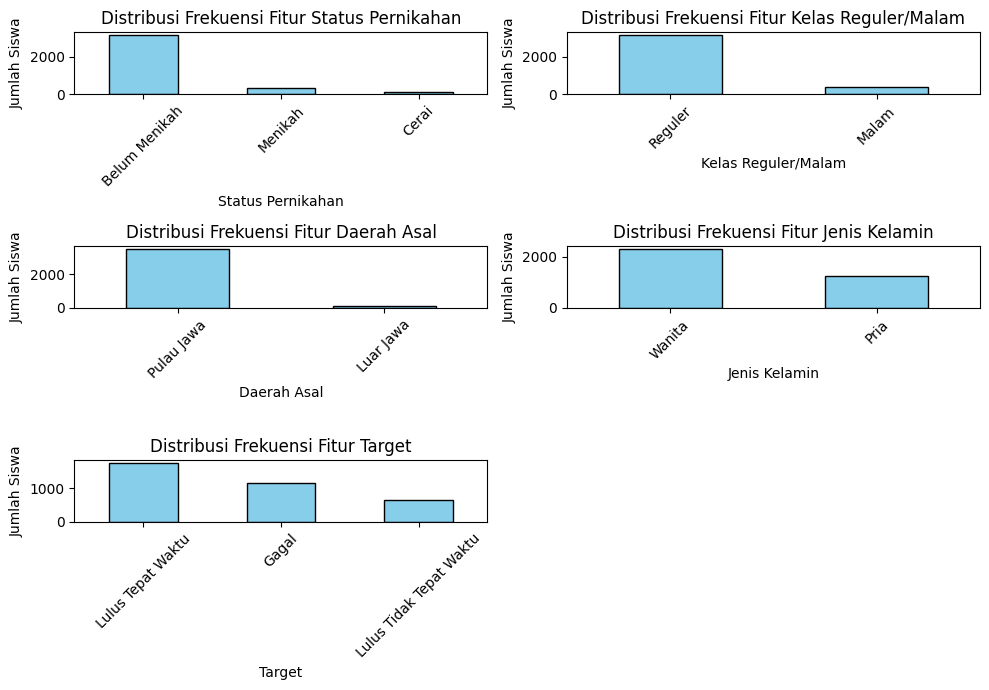

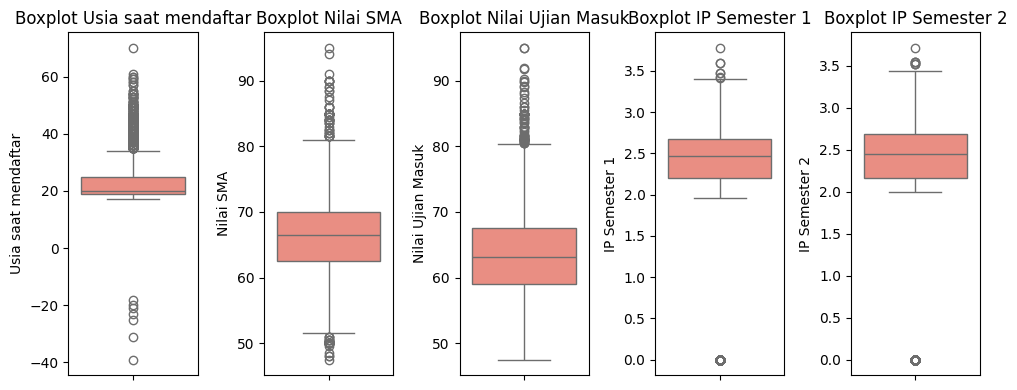




Jumlah data awal sebelum outlier dihapus: 3557 baris

Jumlah data akhir setelah outlier dihapus: 2459 baris

Total outlier yang berhasil dibuang: 1098 baris



In [45]:
# 1)	Hitung histogram setiap fitur, tampilkan dalam bentuk grafik batang

import seaborn as sns
fitur_kategori = ['Status Pernikahan', 'Kelas Reguler/Malam', 'Daerah Asal', 'Jenis Kelamin', 'Target']

plt.figure(figsize=(10, 7))
for i, kolom in enumerate(fitur_kategori, 1):
    plt.subplot(3, 2, i)
    # Menghitung frekuensi nilai unik dan menampilkan grafik batang (bar chart)
    df_gabung[kolom].value_counts().plot(kind='bar', color='skyblue', edgecolor='black')
    plt.title(f'Distribusi Frekuensi Fitur {kolom}')
    plt.xlabel(kolom)
    plt.ylabel('Jumlah Siswa')
    plt.xticks(rotation=45)

plt.tight_layout()
plt.show()
print()
print()

# 2)	Identifikasi outlier dengan boxplot

fitur_numerik = ['Usia saat mendaftar', 'Nilai SMA', 'Nilai Ujian Masuk', 'IP Semester 1', 'IP Semester 2']

plt.figure(figsize=(10, 4))
for i, kolom in enumerate(fitur_numerik, 1):
    plt.subplot(1, 5, i)
    sns.boxplot(y=df_gabung[kolom], color='salmon')
    plt.title(f'Boxplot {kolom}')

plt.tight_layout()
plt.show()
print()
print()

# 3)	Hapus outlier dari data

df_clean = df_gabung.copy()
print(f"\nJumlah data awal sebelum outlier dihapus: {len(df_clean)} baris")


for kolom in fitur_numerik:
    Q1 = df_clean[kolom].quantile(0.25)
    Q3 = df_clean[kolom].quantile(0.75)
    IQR = Q3 - Q1
    batas_bawah = Q1 - 1.5 * IQR
    batas_atas = Q3 + 1.5 * IQR

    if kolom == 'Usia saat mendaftar':
        df_clean = df_clean[(df_clean[kolom] >= batas_bawah) & (df_clean[kolom] <= batas_atas) & (df_clean[kolom] > 0)]
    else:
        df_clean = df_clean[(df_clean[kolom] >= batas_bawah) & (df_clean[kolom] <= batas_atas)]
print(f"\nJumlah data akhir setelah outlier dihapus: {len(df_clean)} baris")
print(f"\nTotal outlier yang berhasil dibuang: {len(df_gabung) - len(df_clean)} baris")
print()


##Task 6
Agar nantinya kita bisa mendapatkan fitur yang relevan, sebaiknya kita melihat hubungan setiap fitur dengan kelas target.

--- Tabel Korelasi Antar Fitur Numerik ---
                     Usia saat mendaftar  Nilai SMA  Nilai Ujian Masuk  \
Usia saat mendaftar             1.000000  -0.101243          -0.031277   
Nilai SMA                      -0.101243   1.000000           0.587557   
Nilai Ujian Masuk              -0.031277   0.587557           1.000000   
IP Semester 1                  -0.146872   0.052855           0.069718   
IP Semester 2                  -0.169710   0.055761           0.077862   

                     IP Semester 1  IP Semester 2  
Usia saat mendaftar      -0.146872      -0.169710  
Nilai SMA                 0.052855       0.055761  
Nilai Ujian Masuk         0.069718       0.077862  
IP Semester 1             1.000000       0.836049  
IP Semester 2             0.836049       1.000000  

--- Analisis Bivariat: Jenis Kelamin vs Target Kelulusan ---
Target         Gagal  Lulus Tepat Waktu  Lulus Tidak Tepat Waktu
Jenis Kelamin                                                   
Pria    

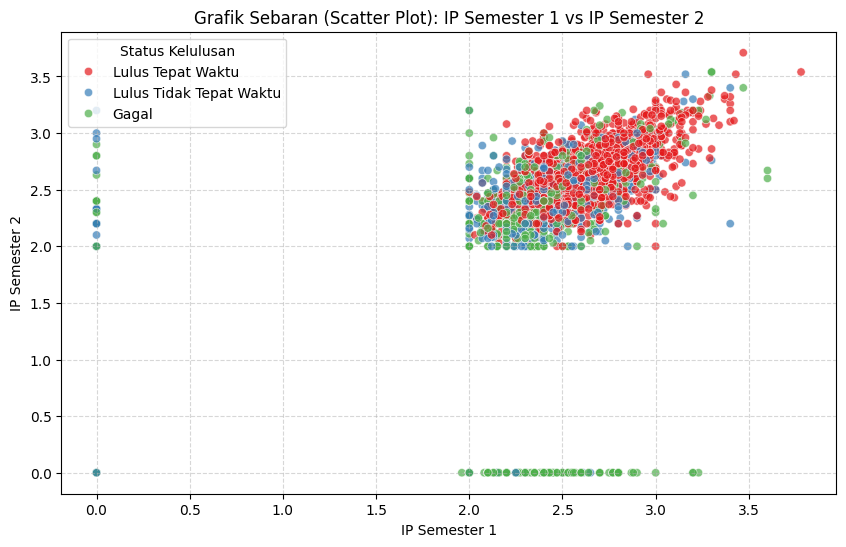

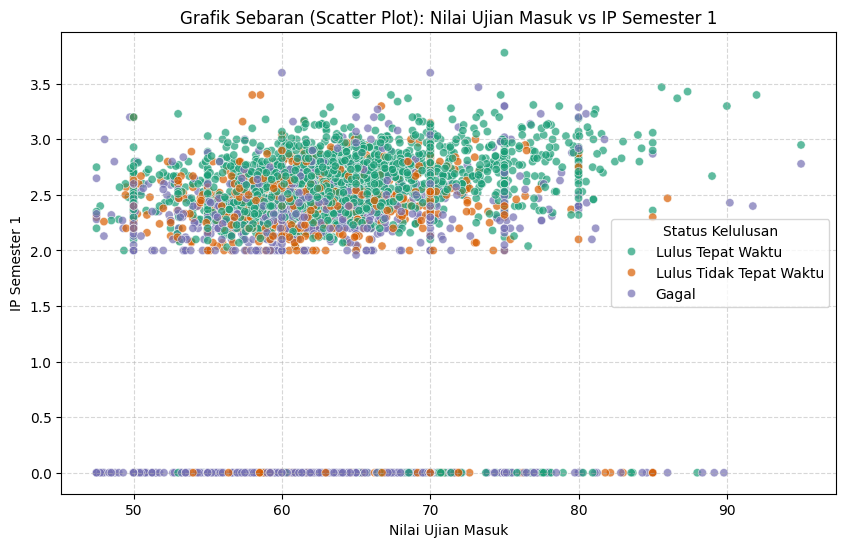

In [46]:
# 1)	Lakukan analisis bivariate

print("--- Tabel Korelasi Antar Fitur Numerik ---")
fitur_numerik = ['Usia saat mendaftar', 'Nilai SMA', 'Nilai Ujian Masuk', 'IP Semester 1', 'IP Semester 2']
tabel_korelasi = df_gabung[fitur_numerik].corr()
print(tabel_korelasi)

print("\n--- Analisis Bivariat: Jenis Kelamin vs Target Kelulusan ---")
tabel_silang = pd.crosstab(df_gabung['Jenis Kelamin'], df_gabung['Target'], normalize='index') * 100
print(tabel_silang.round(2))

# 2)	Plot kedalam grafik sebaran (scatter)

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_gabung,
    x='IP Semester 1',
    y='IP Semester 2',
    hue='Target',
    palette='Set1',
    alpha=0.7
)

plt.title('Grafik Sebaran (Scatter Plot): IP Semester 1 vs IP Semester 2')
plt.xlabel('IP Semester 1')
plt.ylabel('IP Semester 2')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Status Kelulusan')
plt.show()

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_gabung,
    x='Nilai Ujian Masuk',
    y='IP Semester 1',
    hue='Target',
    palette='Dark2',
    alpha=0.7
)

plt.title('Grafik Sebaran (Scatter Plot): Nilai Ujian Masuk vs IP Semester 1')
plt.xlabel('Nilai Ujian Masuk')
plt.ylabel('IP Semester 1')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Status Kelulusan')
plt.show()


##Task 7
Oke, sepertinya sudah siap, tapi kok jumlah data per-kelas nya tidak seimbang ya, ada beberapa algoritma yang akan terpengaruh dengan kondisi ini, kita akan gunakan algoritma **SMOTE (Synthetic Minority Over-sampling Technique)** untuk menyelesaikan masalah ini, jadi kita **akan** melakukan proses augmentasi data karena **metode ini menciptakan set data terolah berdasarkan kedekatan tetangganya (k-nearest neighbors) sehingga ML mampu mengenali pola kelulusan mahasiswa dari semua kelas secara lebih adil dan akurat.**

In [47]:
# 1)	Augmentasi data untuk balancing kelas (Optional)
from imblearn.over_sampling import SMOTE
import numpy as np
import pandas as pd

X = df_gabung.drop(columns=['ID', 'Target'])
y = df_gabung['Target']

X_encoded = pd.get_dummies(X, drop_first=True)
y_encoded = y.astype('category').cat.codes
pemetaan_kelas = dict(enumerate(y.astype('category').cat.categories))

smote = SMOTE(sampling_strategy='auto', random_state=42)
X_resampled, y_resampled = smote.fit_resample(X_encoded, y_encoded)

print("--- HASIL IMPLEMENTASI SMOTE ---")
print(f"Dimensi matriks fitur sebelum SMOTE : {X_encoded.shape}")
print(f"Dimensi matriks fitur setelah SMOTE : {X_resampled.shape}")

print("\nKomposisi kelas data setelah augmentasi:")
nilai_indeks, total_sampel = np.unique(y_resampled, return_counts=True)
for indeks, jumlah in zip(nilai_indeks, total_sampel):
    nama_kelas = pemetaan_kelas[indeks]
    print(f" * Kelas {indeks} ({nama_kelas}): {jumlah} sampel")

--- HASIL IMPLEMENTASI SMOTE ---
Dimensi matriks fitur sebelum SMOTE : (3557, 42)
Dimensi matriks fitur setelah SMOTE : (5271, 42)

Komposisi kelas data setelah augmentasi:
 * Kelas 0 (Gagal): 1757 sampel
 * Kelas 1 (Lulus Tepat Waktu): 1757 sampel
 * Kelas 2 (Lulus Tidak Tepat Waktu): 1757 sampel


Selanjutnya datanya perlu kita bagi dengan ratio **80:20**
Dimana **80%** adalah data training
Dan **20%** adalah data testing


In [24]:
# 1)	Lakukan pembagian data training dan testing
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

print("--- Hasil Pembagian Dataset ---")
print(f"Jumlah sampel Data Training (X_train) : {X_train.shape[0]} baris")
print(f"Jumlah sampel Data Testing (X_test)   : {X_test.shape[0]} baris")
print(f"Total fitur setelah encoding          : {X_encoded.shape[1]} kolom")

--- Hasil Pembagian Dataset ---
Jumlah sampel Data Training (X_train) : 2845 baris
Jumlah sampel Data Testing (X_test)   : 712 baris
Total fitur setelah encoding          : 42 kolom


##Task 8
Sekarang kita mulai training nya

In [51]:
# 1)	Lakukan proses training dengan algoritma yang telah dipilih
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import KFold, cross_val_score
import time
import numpy as np

smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

model_xgb = XGBClassifier(
    n_estimators=100,          # Jumlah pohon keputusan yang akan dibangun (catatan belajar)
    learning_rate=0.1,         # Langkah pengecilan bobot (eta) untuk mencegah overfitting
    max_depth=6,               # Kedalaman maksimum setiap pohon keputusan
    objective='multi:softmax', # Fungsi objektif untuk klasifikasi multi-kelas
    num_class=3,               # Total variasi unik dari kelas target kita
    random_state=42,           # Mengunci kerandoman agar hasil training konsisten
    eval_metric='mlogloss'     # Metrik evaluasi log-loss untuk multi-kelas
)
print("\n--- Memulai Proses Pelatihan Model ---")
print()
waktu_mulai = time.time()
model_xgb.fit(X_train_resampled, y_train_resampled)

waktu_selesai = time.time()
durasi_training = waktu_selesai - waktu_mulai
print()
print(f"Proses training berhasil diselesaikan!")
print()
print(f"Durasi waktu komputasi pelatihan model: {durasi_training:.2f} detik")

# 2)	Lakukan evaluasi model dengan K-fold
# ...
kfold = KFold(n_splits=5, shuffle=True, random_state=42)
print("\n--- Memulai Evaluasi Model dengan 5-Fold Cross Validation ---")
print()
skor_akurasi = cross_val_score(model_xgb, X_train_resampled, y_train_resampled, cv=kfold, scoring='accuracy')
skor_f1 = cross_val_score(model_xgb, X_train_resampled, y_train_resampled, cv=kfold, scoring='f1_macro')
print("\n--- Hasil Validasi K-Fold ---")
print()
print(f"\nAkurasi untuk setiap fold          : {skor_akurasi.round(4)}")
print(f"\nRata-rata Akurasi Model (Mean Acc)  : {np.mean(skor_akurasi) * 100:.2f}%")
print(f"\nStandar Deviasi Akurasi             : {np.std(skor_akurasi) * 100:.2f}%")
print(f"\nRata-rata Skor F1-Macro            : {np.mean(skor_f1) * 100:.2f}%")


--- Memulai Proses Pelatihan Model ---


Proses training berhasil diselesaikan!

Durasi waktu komputasi pelatihan model: 0.42 detik

--- Memulai Evaluasi Model dengan 5-Fold Cross Validation ---


--- Hasil Validasi K-Fold ---


Akurasi untuk setiap fold          : [0.7699 0.777  0.7675 0.7865 0.796 ]

Rata-rata Akurasi Model (Mean Acc)  : 77.94%

Standar Deviasi Akurasi             : 1.06%

Rata-rata Skor F1-Macro            : 77.94%


#Task 9
Training sudah selesai dan model sudah diketahui, kita uji hasilnya dengan data testing untuk melihat kemungkinan overfitting dan underfitting, sekaligus menghitung kualitas model dengan matrik pengukuran


--- Analisis Generalisasi Performa Model ---

Akurasi pada Data Training : 91.79%

Akurasi pada Data Testing  : 71.07%

Kesimpulan: Model mengalami OVERFITTING (Sangat tepat hasilnya di data latihan, tapi kurang di data uji).

--- Laporan Klasifikasi Detil (Data Testing) ---

                         precision    recall  f1-score   support

                  Gagal       0.80      0.72      0.76       231
      Lulus Tepat Waktu       0.76      0.84      0.80       352
Lulus Tidak Tepat Waktu       0.39      0.33      0.35       129

               accuracy                           0.71       712
              macro avg       0.65      0.63      0.64       712
           weighted avg       0.70      0.71      0.70       712



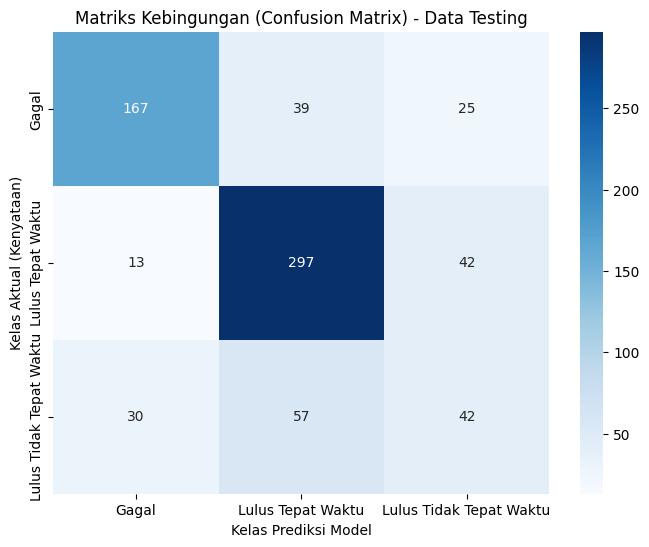

In [52]:
# 1)	Evaluasi dengan data testing

from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
y_pred_train = model_xgb.predict(X_train_resampled)
y_pred_test = model_xgb.predict(X_test)
akurasi_train = accuracy_score(y_train_resampled, y_pred_train) * 100
akurasi_test = accuracy_score(y_test, y_pred_test) * 100
print("\n--- Analisis Generalisasi Performa Model ---")
print(f"\nAkurasi pada Data Training : {akurasi_train:.2f}%")
print(f"\nAkurasi pada Data Testing  : {akurasi_test:.2f}%")

RED_BOLD = "\033[1;31m"
RESET = "\033[0m"

selisih = akurasi_train - akurasi_test
if selisih > 10:
    print(f"\nKesimpulan: Model mengalami {RED_BOLD}OVERFITTING{RESET} (Sangat tepat hasilnya di data latihan, tapi kurang di data uji).")
elif akurasi_train < 60 and akurasi_test < 60:
    print(f"\nKesimpulan: Model mengalami {RED_BOLD}UNDERFITTING{RESET} (Performa model rendah pada kedua data atau kurang menguasai pola).")
else:
    print(f"\nKesimpulan: Model bergeneralisasi dengan {RED_BOLD}BAIK SEIMBANG{RESET} (Performa ok dan konsisten pada data train maupun data test).")

# 2)	Hitung dengan matrik pengukuran

nama_target = [pemetaan_kelas[i] for i in sorted(pemetaan_kelas.keys())]
print("\n--- Laporan Klasifikasi Detil (Data Testing) ---")
print()
print(classification_report(y_test, y_pred_test, target_names=nama_target))

# Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred_test)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=nama_target,
            yticklabels=nama_target)
plt.title('Matriks Kebingungan (Confusion Matrix) - Data Testing')
plt.xlabel('Kelas Prediksi Model')
plt.ylabel('Kelas Aktual (Kenyataan)')
plt.show()

##Task 10
Berdasarkan hasil evaluasi, kita bisa menyimpulkan bahwa model untuk ML ini belum bisa digunakan. Alasannya tentu saja karena overfitting di mana terjadi perbedaan yang besar antara hasil testing dan training. Kata lainnya, model tidak stabil akurasinya di luar pelatihan sehingga kemampuan prediksi ML diragukan hasilnya. Akurasi pada Data Training : 91.79% sementara akurasi pada Data Testing  : 71.07%
Solusinya: mengubah atau setel ulang parameter yang digunakan dalam ML(XGBClassifier)